In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA

In [2]:
# 1. Load dataset
df = pd.read_csv('/content/Iris.csv')

In [3]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [4]:
print('info')
df.info()

info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [5]:
print('\nSummary Statistics')
df.describe()


Summary Statistics


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [6]:
print("\nData Shape")
df.shape


Data Shape


(150, 6)

In [7]:
df.isnull().sum()
df.duplicated().sum()

np.int64(0)

In [8]:
# Count samples in each class
print(df["Species"].value_counts())


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [9]:
# Count samples in each class
print(df["Species"].value_counts())


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


(array([50.,  0.,  0.,  0.,  0., 50.,  0.,  0.,  0., 50.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

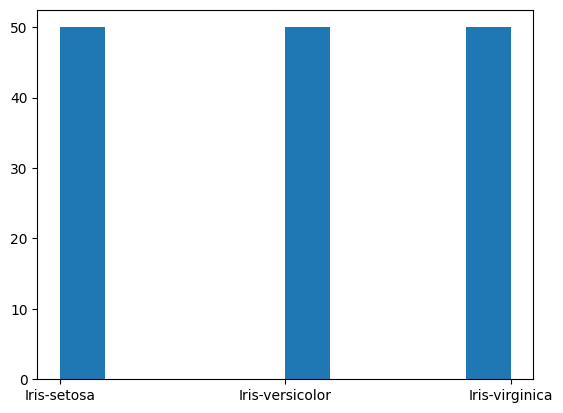

In [10]:
plt.hist(df['Species'])

<Axes: xlabel='Species', ylabel='SepalLengthCm'>

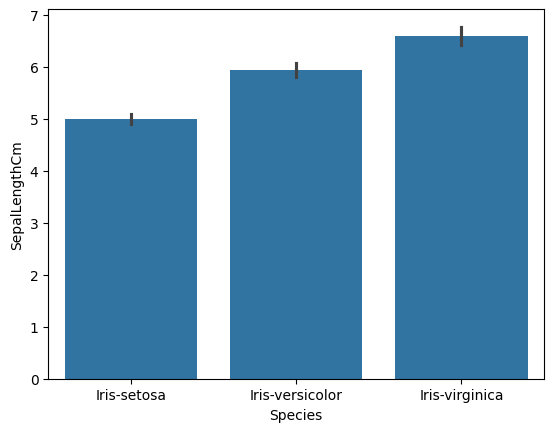

In [11]:
#barplot will be used to show relationship between the Categrical Data and Numerical Data
# Here the SepalLength is the Numerical and SepalLength is Categorical Data

sns.barplot(
    x=df['Species'],
    y=df['SepalLengthCm'],
    data=df
)

<Axes: xlabel='PetalWidthCm', ylabel='Species'>

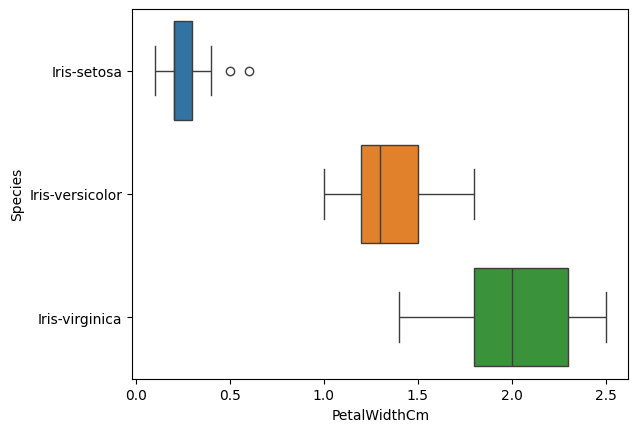

In [12]:
#box plot wil also show the numerical and categorical

sns.boxplot(
    x=df['PetalWidthCm'],
    y=df['Species'],
   hue=df["Species"]
)

<Axes: title={'center': 'Iris dataset'}, ylabel='count'>

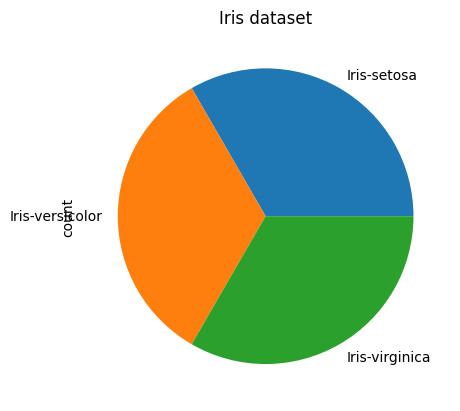

In [13]:

df["Species"].value_counts().plot(
    kind="pie",
    title="Iris dataset"
)

In [14]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


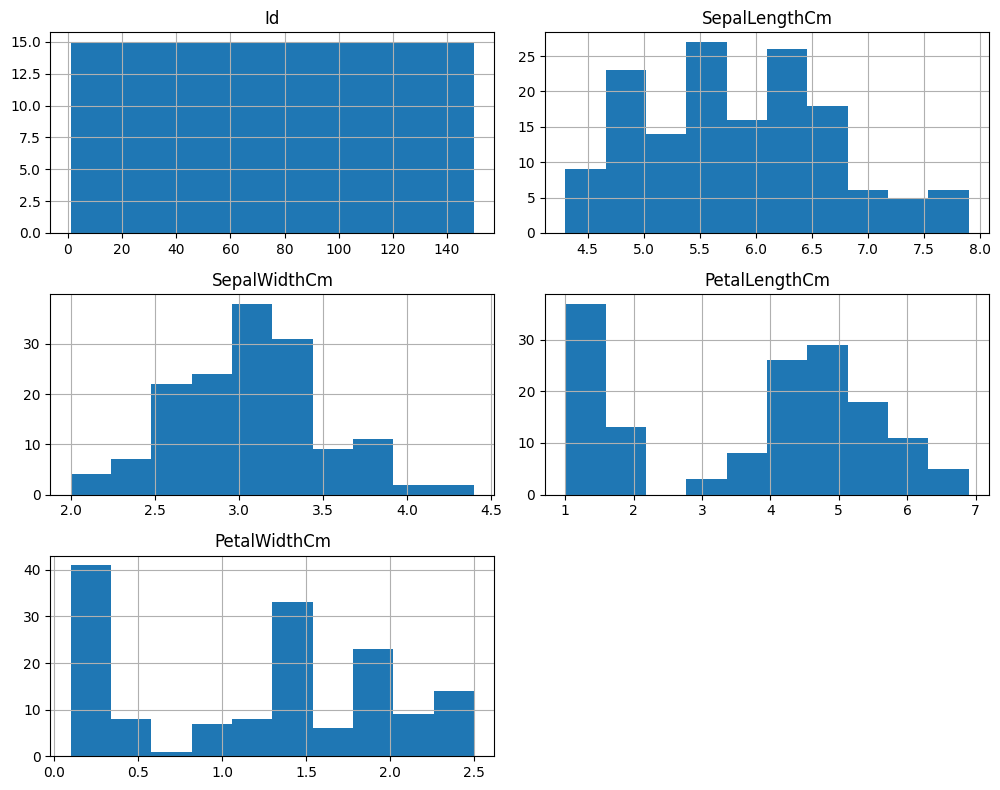

In [15]:
df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

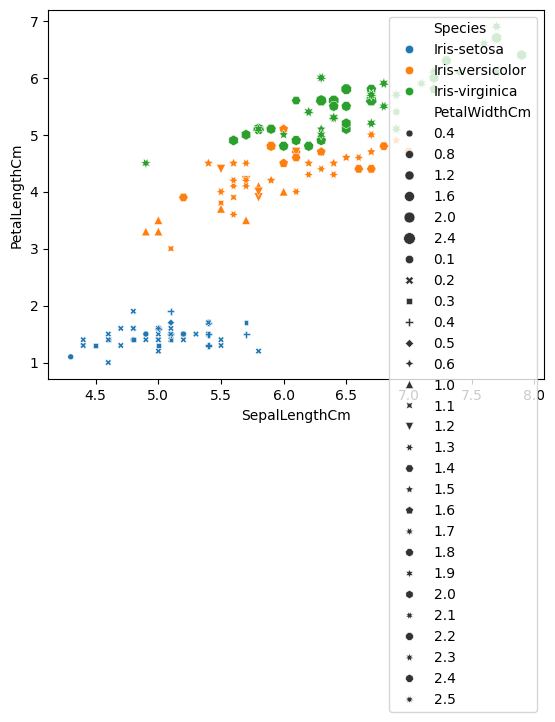

In [16]:
sns.scatterplot(
    data=df,
    x="SepalLengthCm",
    y="PetalLengthCm",
    hue="Species",
    style=df['PetalWidthCm'],
    size=df['PetalWidthCm']
)
plt.show()

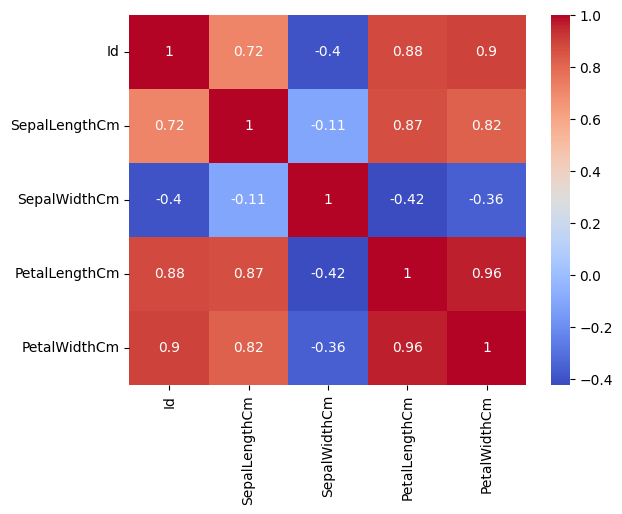

In [17]:
sns.heatmap(
    df.select_dtypes("number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

In [18]:
corr = df.select_dtypes(include="number").corr()

print(corr)

                     Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  \
Id             1.000000       0.716676     -0.397729       0.882747   
SepalLengthCm  0.716676       1.000000     -0.109369       0.871754   
SepalWidthCm  -0.397729      -0.109369      1.000000      -0.420516   
PetalLengthCm  0.882747       0.871754     -0.420516       1.000000   
PetalWidthCm   0.899759       0.817954     -0.356544       0.962757   

               PetalWidthCm  
Id                 0.899759  
SepalLengthCm      0.817954  
SepalWidthCm      -0.356544  
PetalLengthCm      0.962757  
PetalWidthCm       1.000000  


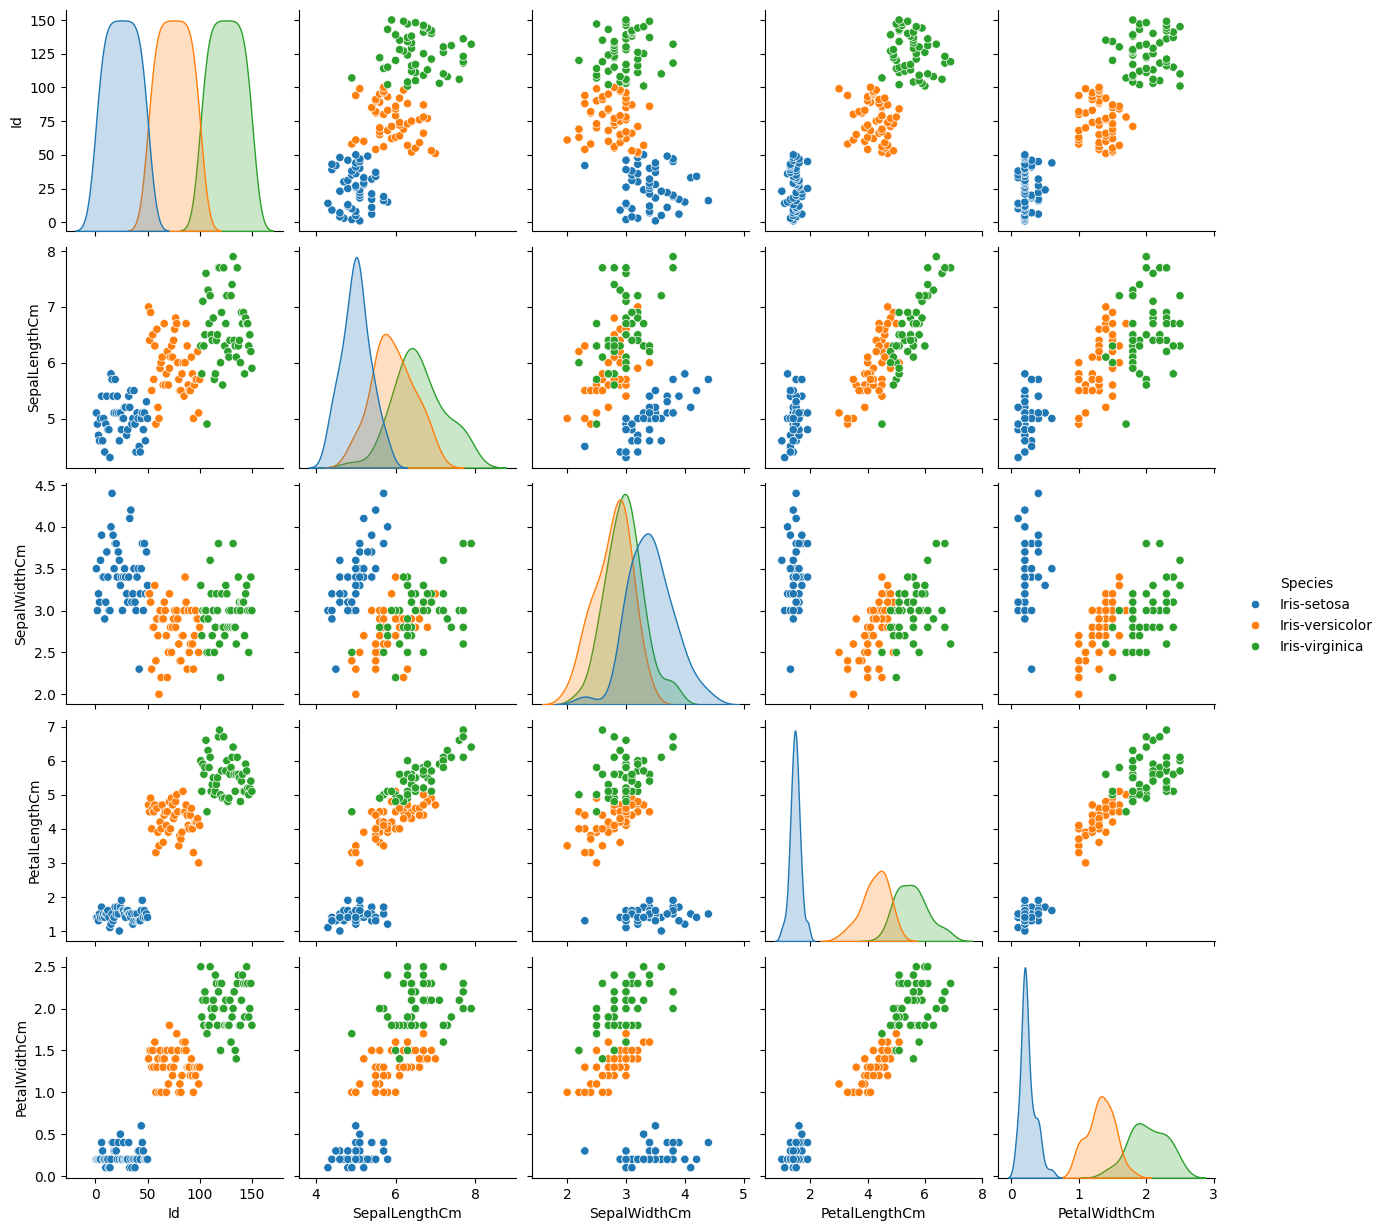

In [19]:
sns.pairplot(df, hue="Species")
plt.show()

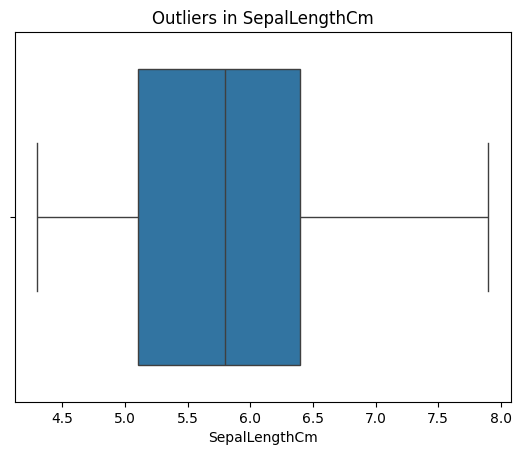

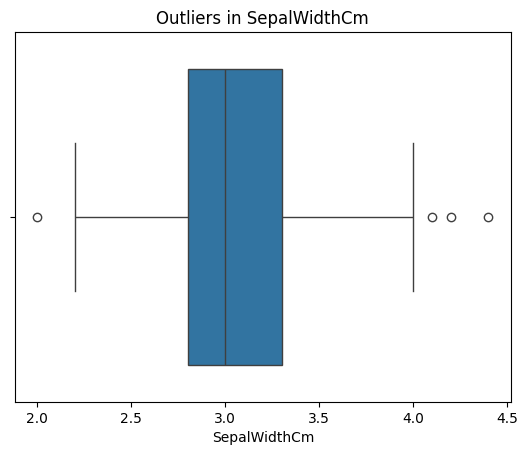

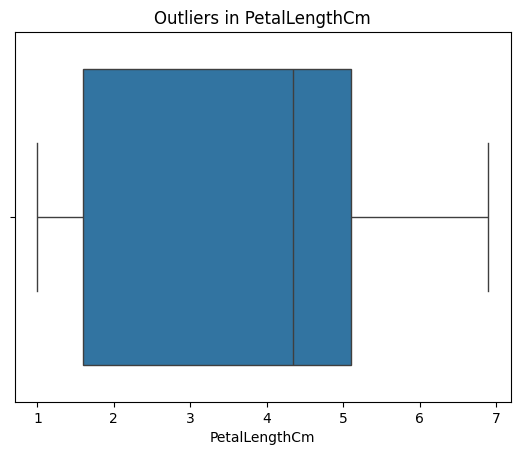

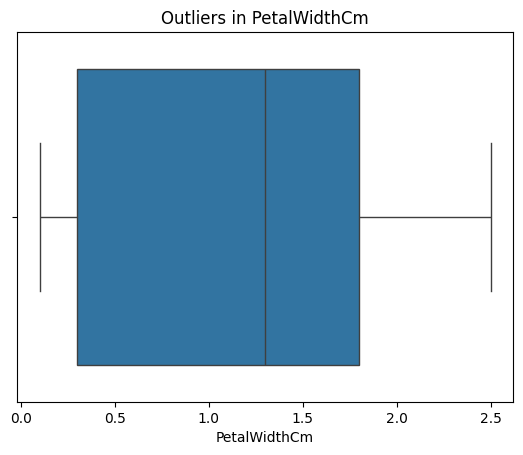

In [20]:
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

for col in features:
    sns.boxplot(x=df[col])
    plt.title(f"Outliers in {col}")
    plt.show()

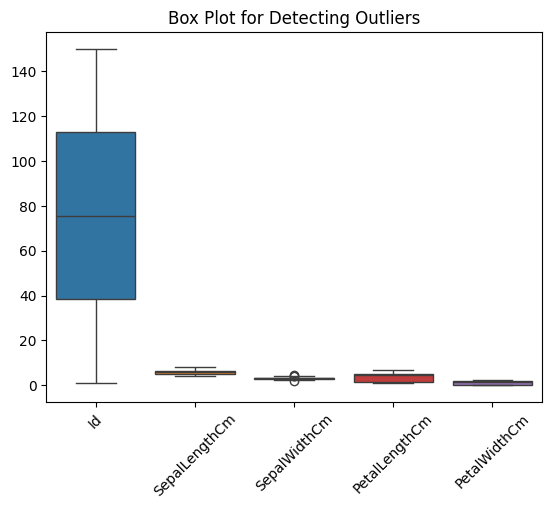

In [21]:
#lets check eht outliers present in the dataSet
# sns.boxplot(
#     x=df['PetalWidthCm'],
#     y=df['Species'],
#    hue=df["Species"]
# )


sns.boxplot(data=df.select_dtypes(include="number"))

plt.title("Box Plot for Detecting Outliers")
plt.xticks(rotation=45)
plt.show()

# Conclusion :
Only the *SepalWidthCm*. Conatains the Ouliers

In [22]:
# WE will use the IQR method to remove the outliers from the DataSet

Q1 = df['SepalWidthCm'].quantile(0.25)
Q3 = df['SepalWidthCm'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Keep only rows within the boundaries
df= df[
    (df['SepalWidthCm'] >= lower_limit) &
    (df['SepalWidthCm'] <= upper_limit)
]


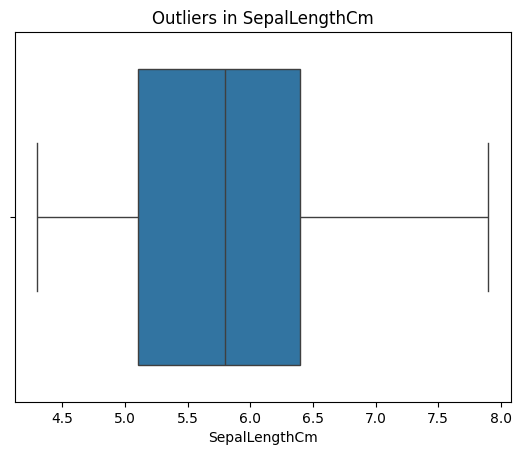

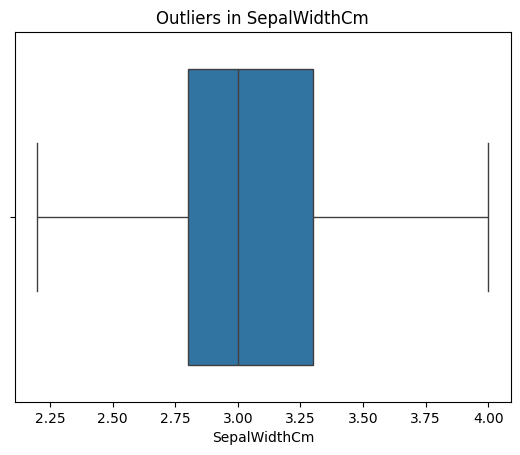

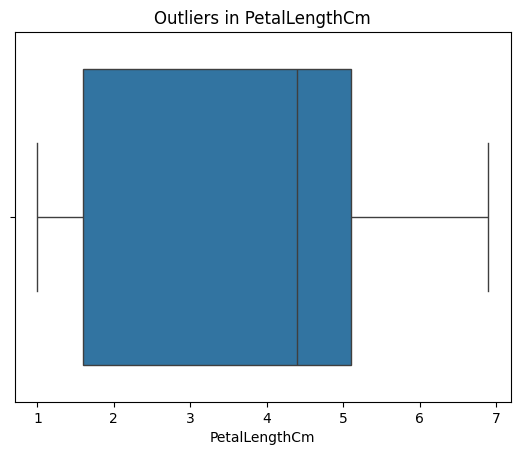

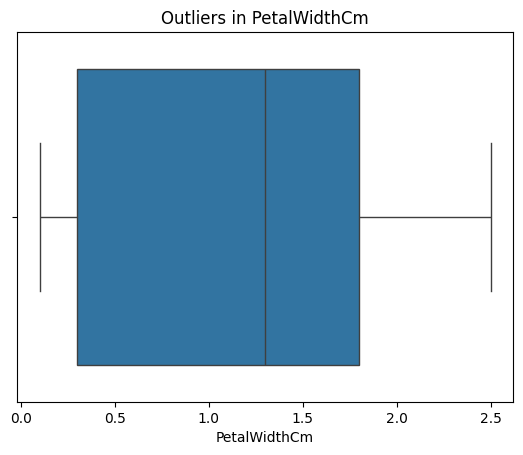

In [23]:
# Again We will check the outliers in the Dataset
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

for col in features:
    sns.boxplot(x=df[col])
    plt.title(f"Outliers in {col}")
    plt.show()


In [24]:
#As we can see that the outliers have been removed from the data

X = df.drop('Species', axis=1)
y = df['Species']

In [25]:
print(X.head())
print(y.head())

print(X.shape)
print(y.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0   1            5.1           3.5            1.4           0.2
1   2            4.9           3.0            1.4           0.2
2   3            4.7           3.2            1.3           0.2
3   4            4.6           3.1            1.5           0.2
4   5            5.0           3.6            1.4           0.2
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object
(146, 5)
(146,)


In [26]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [28]:
X_train_scaled

array([[-1.67549711, -1.03285985,  1.41069256, -1.42794497, -1.41406995],
       [-1.14515825, -0.79347575,  1.16199904, -1.3698047 , -1.41406995],
       [ 1.16066291,  0.28375271, -0.08146857,  0.60696432,  0.77120384],
       [ 1.27595396,  0.64282886, -0.57885561,  1.01394618,  1.31752229],
       [-1.37574036, -0.9131678 ,  1.16199904, -1.42794497, -1.27749034],
       [-1.53714784, -0.55409165,  1.65938608, -1.3698047 , -1.41406995],
       [ 1.50653608, -0.07532345, -0.82754913,  0.72324485,  0.90778345],
       [ 0.26139266, -0.31470755, -0.08146857,  0.1418422 ,  0.08830578],
       [-0.10753873,  0.52313681, -1.32493617,  0.60696432,  0.36146501],
       [-0.52258653,  0.76252091, -0.57885561,  0.43254353,  0.36146501],
       [ 1.43736144,  1.24128911,  0.16722495,  0.89766565,  1.18094268],
       [ 1.41430323,  0.16406066, -0.08146857,  0.54882406,  0.77120384],
       [ 0.88396437,  0.64282886,  0.41591848,  0.83952538,  1.4541019 ],
       [-1.76772996, -0.9131678 ,  1.1

In [29]:

X_test_scaled

array([[-0.6609358 , -0.6737837 ,  1.65938608, -1.3698047 , -1.41406995],
       [ 0.56114941, -0.07532345, -0.82754913,  0.72324485,  0.90778345],
       [-1.12210003, -0.79347575,  0.91330552, -1.42794497, -1.41406995],
       [-1.30656573, -0.55409165,  0.91330552, -1.25352417, -1.41406995],
       [-0.73011044, -1.27224395, -0.08146857, -1.42794497, -1.27749034],
       [ 1.09148827,  1.00190501,  0.664612  ,  1.07208645,  1.18094268],
       [-1.07598361, -1.27224395,  0.16722495, -1.31166444, -1.41406995],
       [ 0.16915981, -0.55409165, -0.08146857,  0.37440326,  0.36146501],
       [-0.15365515,  0.0443686 ,  0.41591848,  0.54882406,  0.77120384],
       [-1.32962394, -0.9131678 ,  1.9080796 , -1.3698047 , -1.27749034],
       [-1.49103142, -1.27224395, -0.08146857, -1.42794497, -1.55064956],
       [ 0.97619721,  0.16406066, -2.07101674,  0.66510459,  0.36146501],
       [ 1.57571071,  1.00190501, -0.08146857,  0.78138512,  1.4541019 ],
       [ 0.12304339, -0.07532345, -0.8

In [30]:
X_train_scaled[-10:]


array([[ 0.33056729,  0.28375271, -0.08146857,  0.43254353,  0.2248854 ],
       [ 0.03081054,  0.16406066, -0.33016209,  0.37440326,  0.36146501],
       [ 1.11454648,  1.60036526,  0.41591848,  1.24650724,  0.77120384],
       [ 1.66794356,  0.0443686 , -0.08146857,  0.72324485,  0.77120384],
       [-1.28350751, -0.9131678 ,  1.65938608, -1.3698047 , -1.14091072],
       [-0.03836409,  0.88221296, -0.08146857,  0.316263  ,  0.2248854 ],
       [ 0.76867331,  0.76252091,  0.41591848,  0.72324485,  1.04436307],
       [-1.444915  , -0.07532345,  2.40546665, -1.5442255 , -1.41406995],
       [ 0.44585835, -0.1950155 , -0.33016209,  0.19998246,  0.08830578],
       [ 0.67644046, -1.1525519 , -1.32493617,  0.37440326,  0.63462423]])

Values have been Scaled

In [34]:
# Train and evaluate

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
# print("Variance retained:", pca.explained_variance_ratio_.sum())

Accuracy: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


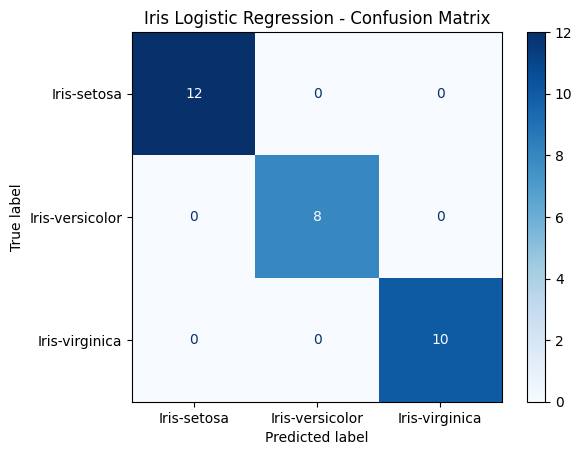

In [35]:
# Consusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt



ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=model.classes_,
    cmap="Blues"
)

plt.title("Iris Logistic Regression - Confusion Matrix")
plt.show()

In [37]:
#  Calculate evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)



accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


# <!-- Feature Conefficiennts -->
Now we will see the feature Coefficients to sess which conefficients

In [38]:
import pandas as pd

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0]
})

print(coefficients)

         Feature  Coefficient
0             Id    -0.096874
1  SepalLengthCm     1.109128
2   SepalWidthCm     0.710248
3  PetalLengthCm    -1.693650
4   PetalWidthCm    -0.809588


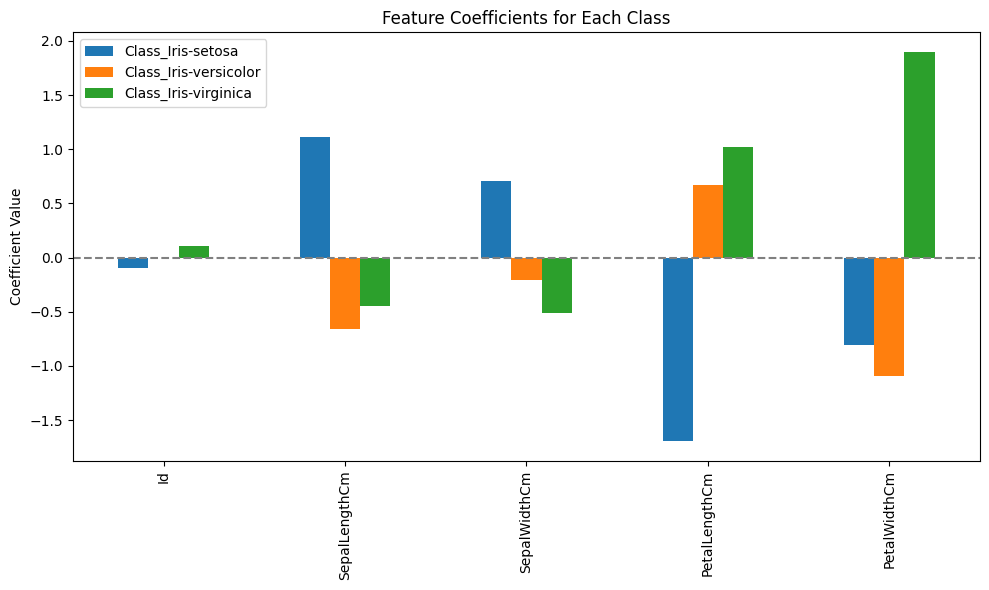

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

coeff_df = pd.DataFrame(
    model.coef_.T,
    index=X.columns,
    columns=[f"Class_{cls}" for cls in model.classes_]
)

coeff_df.plot(kind="bar", figsize=(10, 6))
plt.title("Feature Coefficients for Each Class")
plt.ylabel("Coefficient Value")
plt.axhline(0, color="gray", linestyle="--")
plt.tight_layout()
plt.show()

We can see above that Petal WidthCm is the Largest Factor Contributor that predicts the class_Iris-virginica

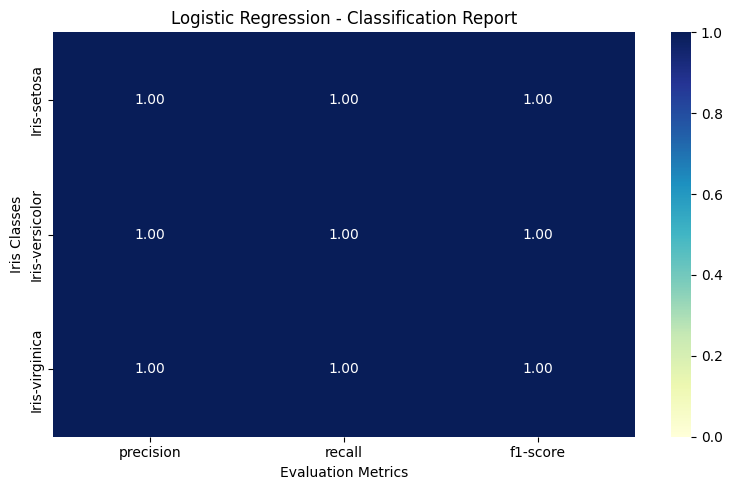

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Predict using your trained Logistic Regression model
y_pred = model.predict(X_test)

# Generate classification report as a dictionary
report = classification_report(
    y_test,
    y_pred,
    target_names=[str(cls) for cls in model.classes_],
    output_dict=True
)

# Convert report into a DataFrame
report_df = pd.DataFrame(report).T

# Keep class metrics and exclude summary rows
report_df = report_df.iloc[:-3, :3]

# Visualize the report
plt.figure(figsize=(8, 5))

sns.heatmap(
    report_df,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    vmin=0,
    vmax=1
)

plt.title("Logistic Regression - Classification Report")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Iris Classes")
plt.tight_layout()
plt.show()